# SynBADD qualitative comparison: NODER and ReMiND

This notebook discovers the newest available fold outputs, joins all methods by the exact ADNI Image Data ID and target visit, randomly selects five eligible subjects, and creates the requested qualitative views. With `RANDOM_SEED = None`, rerunning the selection cell produces a new sample; set an integer seed only when a reproducible sample is needed.

In [36]:
# If needed, uncomment once:
# %pip install nibabel pandas matplotlib torch

from pathlib import Path
import pickle
import re
import warnings

import matplotlib.pyplot as plt
import nibabel as nib
import numpy as np
import pandas as pd
import torch
from IPython.display import display

ROOT = Path(r"/scratch/anirudhkaushik")
N_SUBJECTS = 5
RANDOM_SEED = None       # None = a new random sample per run; set an integer to reproduce a sample
SELECTED_INDEX = 0       # 0..4, used by the SVF and slice-consistency cells
VECINT_STEPS = 7         # scaling-and-squaring steps for SVF integration

assert ROOT.exists(), f"Backup root is unavailable: {ROOT}"
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / 'images').is_dir() and (PROJECT_ROOT.parent / 'images').is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent
IMAGE_DIR = PROJECT_ROOT / 'images'
IMAGE_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 120, "font.size": 10})

In [37]:
# Discovery and exact image-ID indexing. This cell is safe to rerun while files are still arriving.
IMAGE_ID_RE = re.compile(r"_I(\d+)_")
MAIN_MODEL_RE = re.compile(r"CrossAttentionTransformer\+DAFT_Past\+Future_Fold([1-5])$")

def image_id(path):
    m = IMAGE_ID_RE.search(path.name)
    return f"I{m.group(1)}" if m else None

def resolve_scratch_path(value):
    if pd.isna(value):
        return None
    raw = str(value).replace('\\', '/')
    prefix = '/scratch/anirudhkaushik/'
    rel = raw.split(prefix, 1)[1] if prefix in raw else raw.lstrip('/')
    for p in (ROOT / rel, ROOT / 'data' / rel, Path(str(value))):
        if p.exists():
            return p
    return ROOT / rel  # useful diagnostic path even if backup is incomplete

def choose_flat_result_dir(name):
    candidates = [ROOT / name, ROOT / 'data' / name]
    candidates = [p for p in candidates if p.is_dir()]
    if not candidates:
        return None
    # Prefer the most complete copy, then the newest one.
    return max(candidates, key=lambda p: (sum(1 for _ in p.glob('*.nii*')), p.stat().st_mtime))

def main_synbadd_candidates(fold):
    bases = [
        ROOT / f'SYNBADD_Qualitative_{fold}',
        ROOT / 'data' / f'SYNBADD_Qualitative_{fold}',
        ROOT / 'SYNBADD_outputs' / f'SYNBADD_Qualitative_{fold}',
    ]
    found = []
    for base in bases:
        if not base.is_dir():
            continue
        for p in [base, *[q for q in base.rglob('*') if q.is_dir()]]:
            if MAIN_MODEL_RE.search(p.name) and '_mask' not in p.name and 'experiment_' not in str(p):
                n_scans = sum(1 for q in p.glob('*_all_synthetic.nii.gz'))
                n_fields = sum(1 for q in p.glob('*_all_synthetic_field.nii.gz'))
                found.append((min(n_scans, n_fields), p.stat().st_mtime, p))
    return max(found, default=(0, 0, None))[2]

def index_outputs(folder, kind):
    out = {}
    if folder is None:
        return out
    for p in folder.glob('*.nii*'):
        iid = image_id(p)
        if iid is None:
            continue
        if kind == 'syn_scan' and p.name.endswith('_all_synthetic.nii.gz'):
            out[iid] = p
        elif kind == 'syn_field' and p.name.endswith('_all_synthetic_field.nii.gz'):
            out[iid] = p
        elif kind in {'noder', 'remind'}:
            out[iid] = p
    return out

meta_candidates = [ROOT / 'svf_metadata.csv', ROOT / 'data' / 'svf_metadata.csv']
META_PATH = max((p for p in meta_candidates if p.exists()), key=lambda p: p.stat().st_mtime)
metadata = pd.read_csv(META_PATH)

fold_dirs = {}
indexes = {}
for fold in range(1, 6):
    fold_dirs[fold] = {
        'SynBADD': main_synbadd_candidates(fold),
        'NODER': choose_flat_result_dir(f'NODER_result_{fold}'),
        'ReMiND': choose_flat_result_dir(f'remind_results_{fold}'),
    }
    indexes[fold] = {
        'syn': index_outputs(fold_dirs[fold]['SynBADD'], 'syn_scan'),
        'field': index_outputs(fold_dirs[fold]['SynBADD'], 'syn_field'),
        'noder': index_outputs(fold_dirs[fold]['NODER'], 'noder'),
        'remind': index_outputs(fold_dirs[fold]['ReMiND'], 'remind'),
    }

display(pd.DataFrame(fold_dirs).T.rename_axis('fold'))

,SynBADD,NODER,ReMiND
fold,,,
1,/scratch/anirudhkaushik/SYNBADD_Qualitative_1/...,/scratch/anirudhkaushik/NODER_result_1,/scratch/anirudhkaushik/remind_results_1
2,/scratch/anirudhkaushik/SYNBADD_Qualitative_2/...,/scratch/anirudhkaushik/NODER_result_2,/scratch/anirudhkaushik/remind_results_2
3,/scratch/anirudhkaushik/SYNBADD_Qualitative_3/...,/scratch/anirudhkaushik/NODER_result_3,/scratch/anirudhkaushik/remind_results_3
4,/scratch/anirudhkaushik/SYNBADD_Qualitative_4/...,/scratch/anirudhkaushik/NODER_result_4,/scratch/anirudhkaushik/remind_results_4
5,/scratch/anirudhkaushik/SYNBADD_Qualitative_5/...,/scratch/anirudhkaushik/NODER_result_5,/scratch/anirudhkaushik/remind_results_5


In [38]:
# Build eligible exact matches, choose one target visit per subject, then sample five subjects.
rows = []
for _, r in metadata.iterrows():
    iid = str(r['Image Data ID'])
    for fold in range(1, 6):
        if str(r.get(f'fold_{fold}', '')).lower() != 'test':
            continue
        ix = indexes[fold]
        if not all(iid in ix[k] for k in ('syn', 'field', 'noder', 'remind')):
            continue
        target = resolve_scratch_path(r['File_Path'])
        gt_svf = resolve_scratch_path(r['SVF_Path'])
        subject_rows = metadata[metadata['Subject'].astype(str) == str(r['Subject'])].copy()
        subject_rows['_visit_num'] = subject_rows['Visit'].astype(str).str.extract(r'(\d+)')[0].astype(float)
        baseline_row = subject_rows.sort_values('_visit_num').iloc[0]
        baseline = resolve_scratch_path(baseline_row['File_Path'])
        required = [target, baseline, ix['syn'][iid], ix['field'][iid], ix['noder'][iid], ix['remind'][iid]]
        if all(p is not None and p.exists() for p in required):
            rows.append({
                'subject': str(r['Subject']), 'group': r['Group'], 'sex': r['Sex'],
                'age': r['Age'], 'visit': r['Visit'],
                'image_id': iid, 'fold': fold, 'baseline_visit': baseline_row['Visit'],
                'target': target, 'baseline': baseline, 'ground_truth_svf': gt_svf,
                'SynBADD': ix['syn'][iid], 'SynBADD_field': ix['field'][iid],
                'NODER': ix['noder'][iid], 'ReMiND': ix['remind'][iid],
            })

eligible = pd.DataFrame(rows)
if eligible.empty:
    raise RuntimeError('No complete exact matches yet. Re-run after more of the F: backup arrives.')
rng = np.random.default_rng(RANDOM_SEED)
subjects = rng.choice(eligible['subject'].unique(), size=min(N_SUBJECTS, eligible['subject'].nunique()), replace=False)
selected = (eligible[eligible.subject.isin(subjects)]
            .assign(_random=rng.random(sum(eligible.subject.isin(subjects))))
            .sort_values('_random').groupby('subject', as_index=False).first()
            .sort_values(['fold', 'subject']).reset_index(drop=True))
display(selected[['subject', 'group', 'sex', 'age', 'visit', 'image_id', 'fold', 'baseline_visit']])
print(f'{len(eligible)} exact target matches across {eligible.subject.nunique()} subjects are currently available.')

,subject,group,sex,age,visit,image_id,fold,baseline_visit
0,027_S_0307,MCI,M,80,m18,I83021,1,m06
1,116_S_0487,AD,M,78,m12,I80689,1,m06
2,012_S_0637,CN,F,77,m12,I118737,3,m06
3,033_S_0922,MCI,M,69,m06,I66583,3,m06
4,041_S_1260,MCI,M,72,m12,I97125,3,m06


1166 exact target matches across 377 subjects are currently available.


Saved figure: /root/anirudhkaushik/SYNBADD-rebased/images/difference-maps-027_S_0307.png


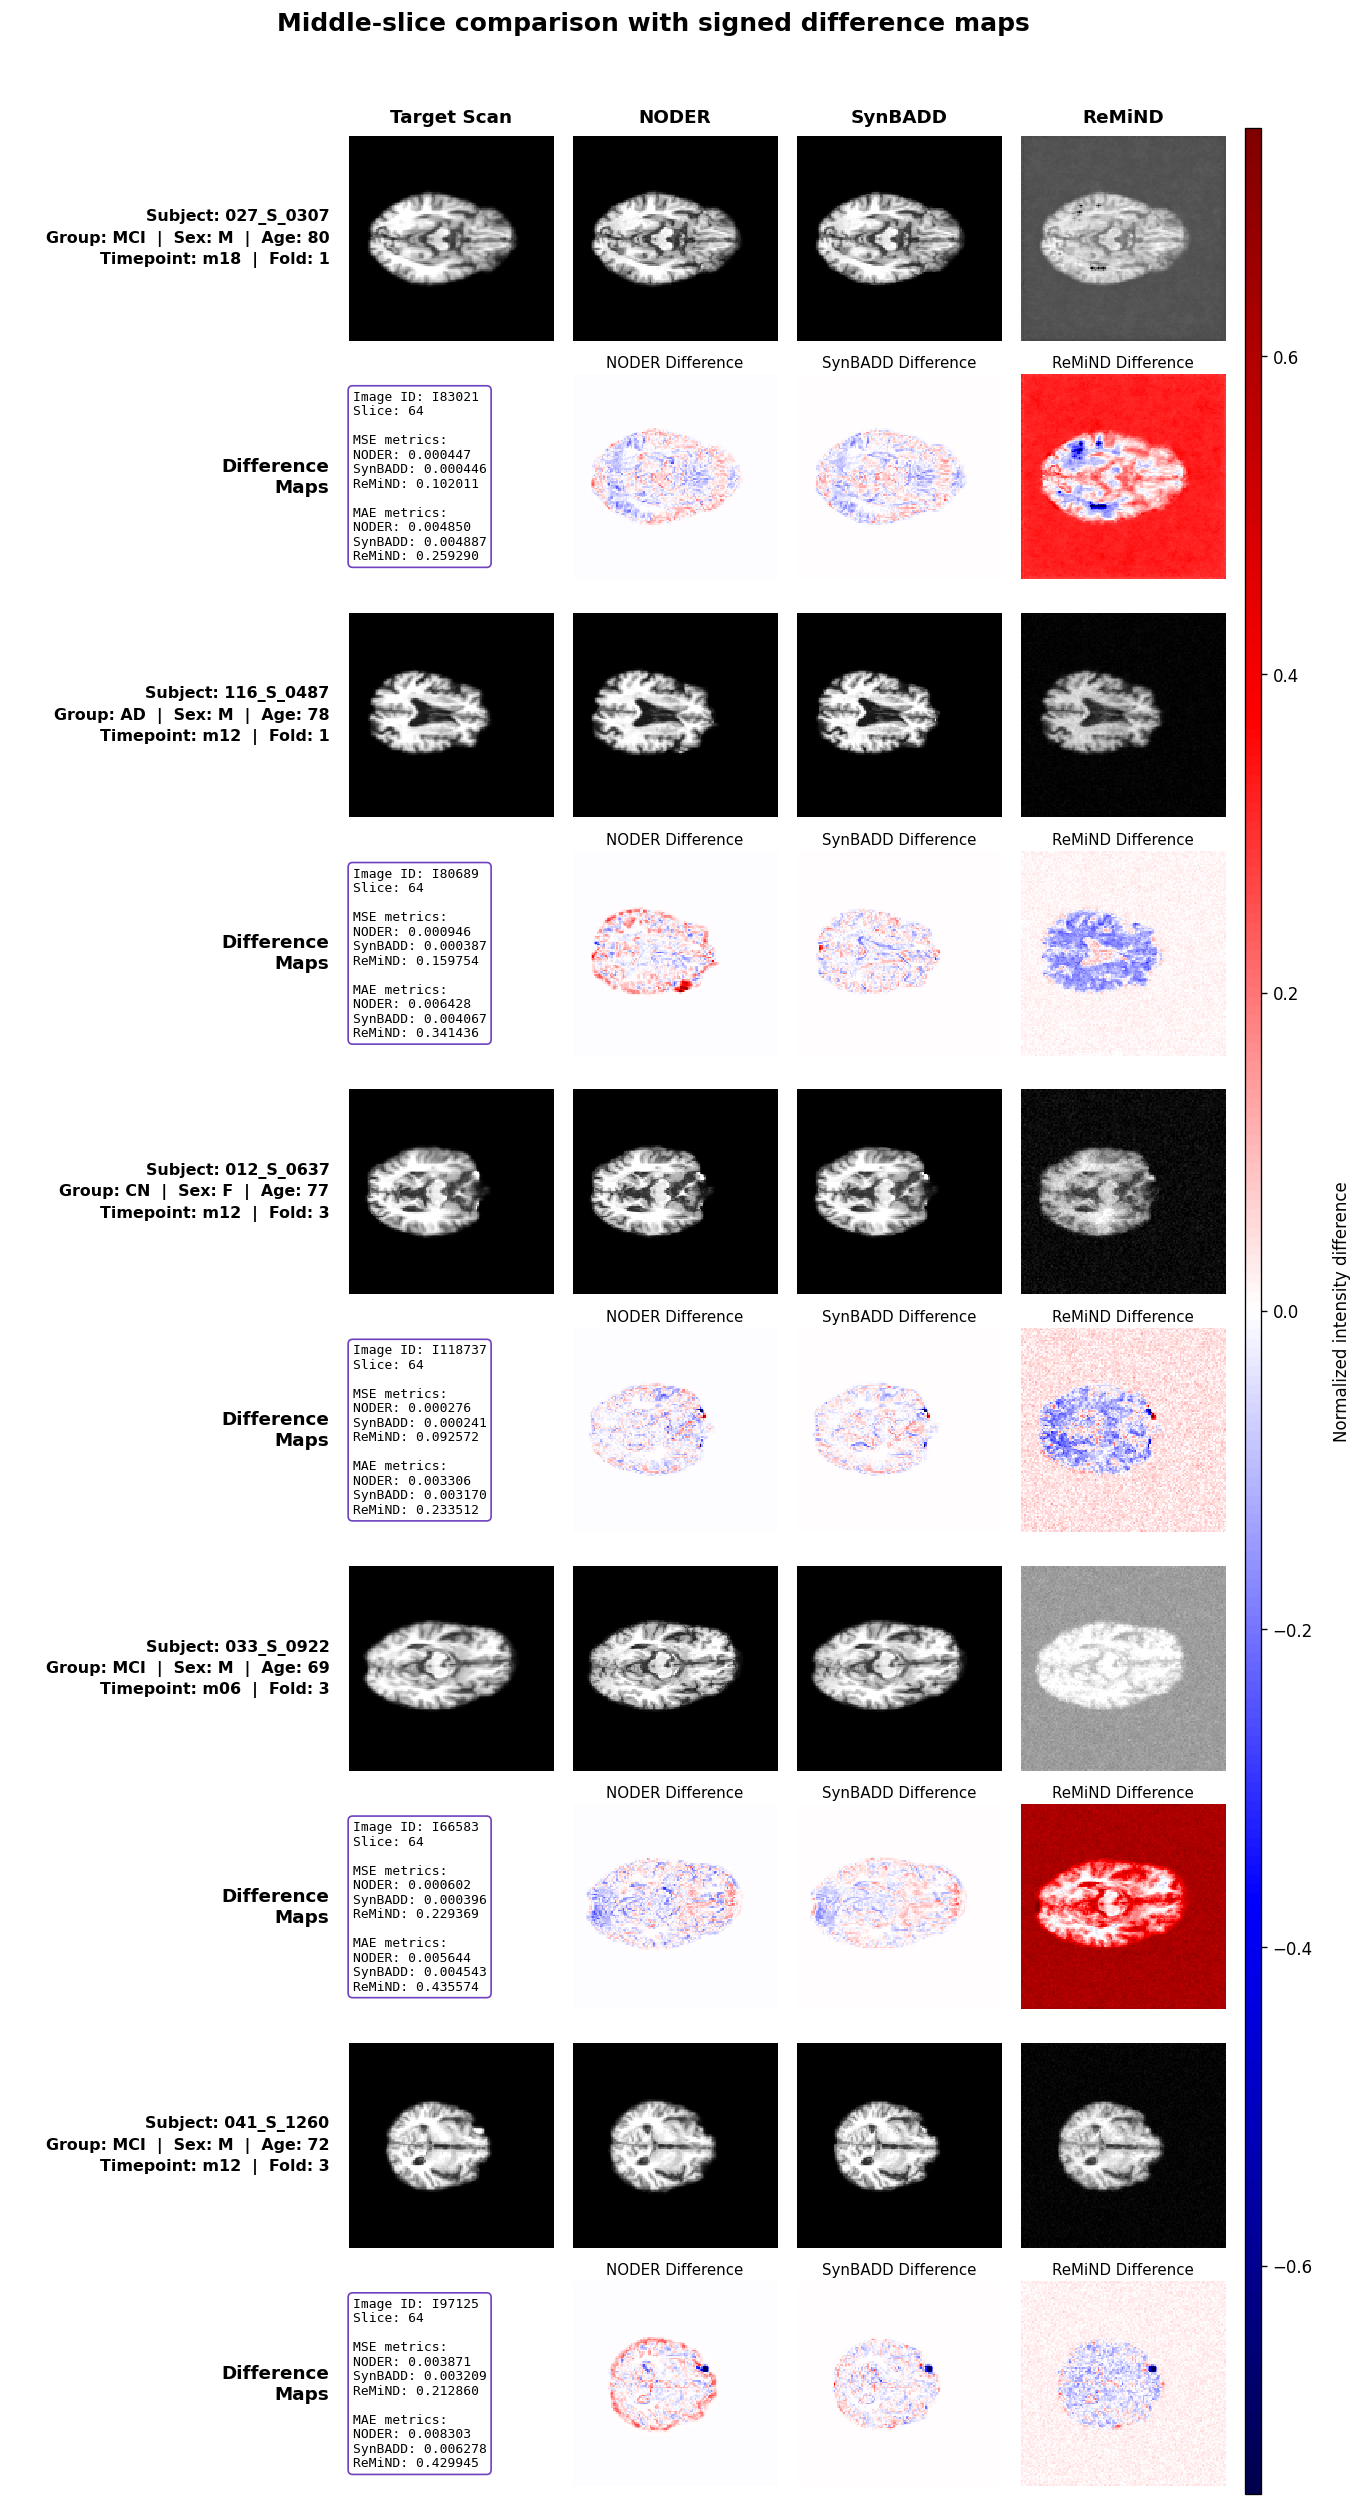

In [39]:
# Helpers and requested middle-axial comparison: Target | NODER | SynBADD | ReMiND
# Headers/affines are unreliable for these files. Read only the stored voxel
# arrays and remove leading singleton batch/channel dimensions.
def load_volume(path):
    vol = np.asarray(nib.load(str(path)).dataobj, dtype=np.float32)
    while vol.ndim > 3 and vol.shape[0] == 1:
        vol = vol[0]
    if vol.ndim != 3:
        raise ValueError(f'Expected a 3D volume, got {vol.shape} from {path}')
    return vol

def robust01(vol):
    finite = vol[np.isfinite(vol)]
    lo, hi = np.percentile(finite, (0.5, 99.5))
    return np.clip((vol - lo) / max(hi - lo, 1e-8), 0, 1)

def axial(vol, z=None):
    z = vol.shape[2] // 2 if z is None else int(np.clip(z, 0, vol.shape[2] - 1))
    return np.rot90(vol[:, :, z], k=-1)  # 90 degrees clockwise: front to back

def save_figure(fig, stem, subject):
    safe_subject = re.sub(r'[^A-Za-z0-9_-]+', '_', str(subject))
    path = IMAGE_DIR / f'{stem}-{safe_subject}.png'
    fig.savefig(path, dpi=300, bbox_inches='tight', facecolor='white')
    print(f'Saved figure: {path}')
    return path

# Reference-style layout: one scan row and one signed-difference row per subject.
scan_methods = ['target', 'NODER', 'SynBADD', 'ReMiND']
prediction_methods = scan_methods[1:]
cases = []
for _, r in selected.iterrows():
    volumes = {m: robust01(load_volume(r[m])) for m in scan_methods}
    target = volumes['target']
    for method in prediction_methods:
        if volumes[method].shape != target.shape:
            raise ValueError(f'Shape mismatch for {r.image_id}: target {target.shape}, '
                             f'{method} {volumes[method].shape}')
    differences = {m: volumes[m] - target for m in prediction_methods}
    metrics = {
        m: {'mse': float(np.mean(differences[m] ** 2)),
            'mae': float(np.mean(np.abs(differences[m])))}
        for m in prediction_methods
    }
    cases.append((r, volumes, differences, metrics))

# A robust common scale preserves the same blue–white–red meaning in every panel.
difference_scale = max(np.percentile(np.abs(d), 99)
                       for _, _, diffs, _ in cases for d in diffs.values())
n_cases = len(cases)
fig = plt.figure(figsize=(11.5, 4.15 * n_cases + 0.8), facecolor='white')
gs = fig.add_gridspec(2 * n_cases, 6,
                      width_ratios=[1.55, 1, 1, 1, 1, 0.08],
                      hspace=0.08, wspace=0.10,
                      left=0.035, right=0.94, top=0.94, bottom=0.025)
column_titles = ['Target Scan', 'NODER', 'SynBADD', 'ReMiND']
difference_image = None

for case_i, (r, volumes, differences, metrics) in enumerate(cases):
    scan_row, diff_row = 2 * case_i, 2 * case_i + 1

    meta_ax = fig.add_subplot(gs[scan_row, 0])
    meta_ax.axis('off')
    meta_ax.text(1.0, 0.5,
                 f'Subject: {r.subject}\nGroup: {r.group}  |  Sex: {r.sex}  |  Age: {r.age}\n'
                 f'Timepoint: {r.visit}  |  Fold: {r.fold}',
                 ha='right', va='center', fontsize=9.5, fontweight='semibold', linespacing=1.45)

    label_ax = fig.add_subplot(gs[diff_row, 0])
    label_ax.axis('off')
    label_ax.text(1.0, 0.5, 'Difference\nMaps', ha='right', va='center',
                  fontsize=11, fontweight='bold')

    for col_i, method in enumerate(scan_methods, start=1):
        ax = fig.add_subplot(gs[scan_row, col_i])
        ax.imshow(axial(volumes[method]), cmap='gray', vmin=0, vmax=1,
                  interpolation='nearest')
        ax.set_box_aspect(1)
        ax.axis('off')
        if case_i == 0:
            ax.set_title(column_titles[col_i - 1], fontsize=11, fontweight='bold', pad=8)

    # Put image-level metrics in the target-minus-target slot, as in the reference.
    metrics_ax = fig.add_subplot(gs[diff_row, 1])
    metrics_ax.axis('off')
    metrics_text = (
        f'Image ID: {r.image_id}\n'
        f'Slice: {volumes["target"].shape[2] // 2}\n\n'
        'MSE metrics:\n'
        + '\n'.join(f'{m}: {metrics[m]["mse"]:.6f}' for m in prediction_methods)
        + '\n\nMAE metrics:\n'
        + '\n'.join(f'{m}: {metrics[m]["mae"]:.6f}' for m in prediction_methods)
    )
    metrics_ax.text(0.02, 0.5, metrics_text, ha='left', va='center', fontsize=7.8,
                    family='monospace', linespacing=1.15,
                    bbox=dict(boxstyle='round,pad=0.35', facecolor='white',
                              edgecolor='#6f42c1', linewidth=1.0))
    for col_i, method in enumerate(prediction_methods, start=2):
        ax = fig.add_subplot(gs[diff_row, col_i])
        difference_image = ax.imshow(axial(differences[method]), cmap='seismic',
                                     vmin=-difference_scale, vmax=difference_scale,
                                     interpolation='nearest')
        ax.set_box_aspect(1)
        ax.axis('off')
        ax.set_title(f'{method} Difference', fontsize=9, pad=4)

cax = fig.add_subplot(gs[:, 5])
colorbar = fig.colorbar(difference_image, cax=cax)
colorbar.set_label('Normalized intensity difference', rotation=90, labelpad=12)
fig.suptitle('Middle-slice comparison with signed difference maps',
             fontsize=15, fontweight='semibold', y=0.985)
difference_maps_path = save_figure(fig, 'difference-maps', selected.iloc[0].subject)
plt.show()

In [40]:
# Difference maps are included directly beneath each subject in the middle-slice figure above.


Saved figure: /root/anirudhkaushik/SYNBADD-rebased/images/deformation-view-027_S_0307.png


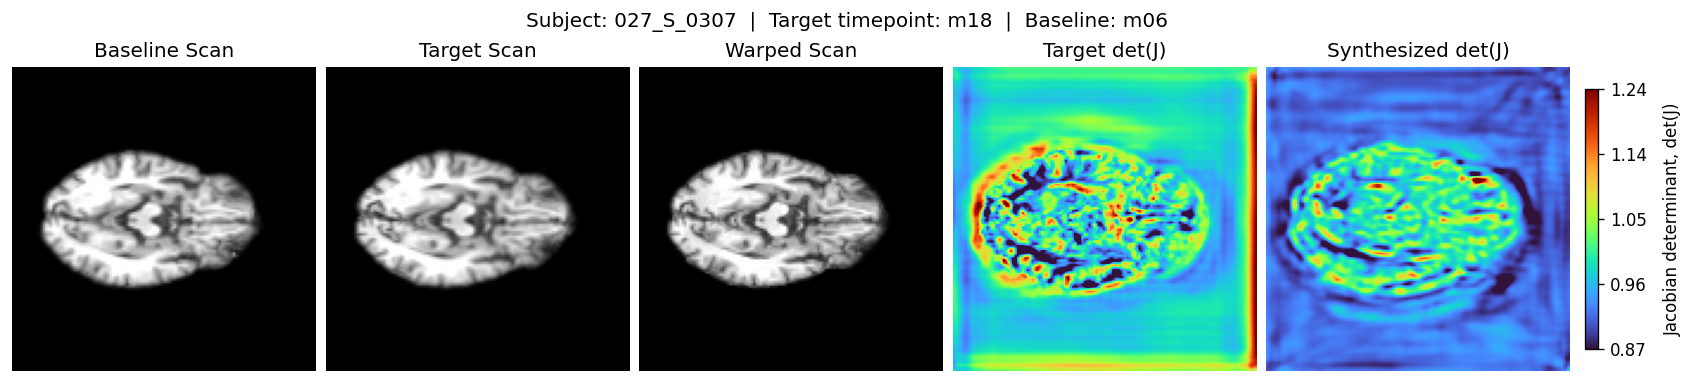

In [41]:
# SynBADD deformation view: baseline, target, warped scan, target det(J), generated det(J).
# Both SVFs are integrated by scaling-and-squaring before det(J) is calculated.
from synbadd.models.spatial_ops import VecInt

def field_channels_first(value):
    if isinstance(value, dict):
        for key in ('svf', 'field', 'flow', 'velocity', 'disp'):
            if key in value:
                value = value[key]; break
        else:
            value = next(v for v in value.values() if hasattr(v, 'shape'))
    a = value.detach().cpu().numpy() if torch.is_tensor(value) else np.asarray(value)
    a = np.squeeze(a)
    if a.ndim != 4:
        raise ValueError(f'Expected a 3-D vector field, got {a.shape}')
    if a.shape[0] == 3:
        return a.astype(np.float32)
    if a.shape[-1] == 3:
        return np.moveaxis(a, -1, 0).astype(np.float32)
    raise ValueError(f'Cannot locate vector components in {a.shape}')

def load_svf(path):
    if path is None or not Path(path).exists():
        raise FileNotFoundError(f'SVF is not backed up yet: {path}')
    if str(path).endswith('.pt'):
        try:
            value = torch.load(path, map_location='cpu', weights_only=True)
        except (TypeError, RuntimeError, pickle.UnpicklingError):
            # These are trusted, locally generated dataset files containing MONAI MetaTensor objects.
            value = torch.load(path, map_location='cpu', weights_only=False)
    else:
        value = np.asarray(nib.load(str(path)).dataobj)
    return field_channels_first(value)

def integrate_svf(svf, steps=VECINT_STEPS):
    x = torch.from_numpy(svf[None]).float()
    with torch.no_grad():
        return VecInt(tuple(svf.shape[1:]), steps)(x)[0].cpu().numpy()

def jacobian_determinant(displacement):
    # displacement component order follows the model's (D,H,W) convention.
    g = [[np.gradient(displacement[i], axis=j) for j in range(3)] for i in range(3)]
    j00, j01, j02 = 1 + g[0][0], g[0][1], g[0][2]
    j10, j11, j12 = g[1][0], 1 + g[1][1], g[1][2]
    j20, j21, j22 = g[2][0], g[2][1], 1 + g[2][2]
    return j00*(j11*j22-j12*j21) - j01*(j10*j22-j12*j20) + j02*(j10*j21-j11*j20)

r = selected.iloc[SELECTED_INDEX]
gt_det = jacobian_determinant(integrate_svf(load_svf(r.ground_truth_svf)))
pred_det = jacobian_determinant(integrate_svf(load_svf(r.SynBADD_field)))
panels = [
    ('Baseline Scan', axial(robust01(load_volume(r.baseline)))),
    ('Target Scan', axial(robust01(load_volume(r.target)))),
    ('Warped Scan', axial(robust01(load_volume(r.SynBADD)))),
    ('Target det(J)', axial(gt_det)),
    ('Synthesized det(J)', axial(pred_det)),
]
fig, axes = plt.subplots(1, 5, figsize=(14, 3.2), layout='constrained')
det_lo = min(np.percentile(gt_det, 1), np.percentile(pred_det, 1))
det_hi = max(np.percentile(gt_det, 99), np.percentile(pred_det, 99))
det_image = None
for i, (title, image) in enumerate(panels):
    if i < 3: axes[i].imshow(image, cmap='gray', vmin=0, vmax=1)
    else: det_image = axes[i].imshow(image, cmap='turbo', vmin=det_lo, vmax=det_hi)
    axes[i].set_box_aspect(1)
    axes[i].set_title(title); axes[i].axis('off')
det_ticks = np.linspace(det_lo, det_hi, 5)
det_colorbar = fig.colorbar(det_image, ax=axes[3:], location='right',
                            shrink=0.78, pad=0.025, ticks=det_ticks, format='%.2f')
det_colorbar.set_label('Jacobian determinant, det(J)', rotation=90, labelpad=10)
fig.suptitle(f'Subject: {r.subject}  |  Target timepoint: {r.visit}  |  Baseline: {r.baseline_visit}')
deformation_view_path = save_figure(fig, 'deformation-view', r.subject)
plt.show()

Saved figure: /root/anirudhkaushik/SYNBADD-rebased/images/slice-level-consistence-027_S_0307.png


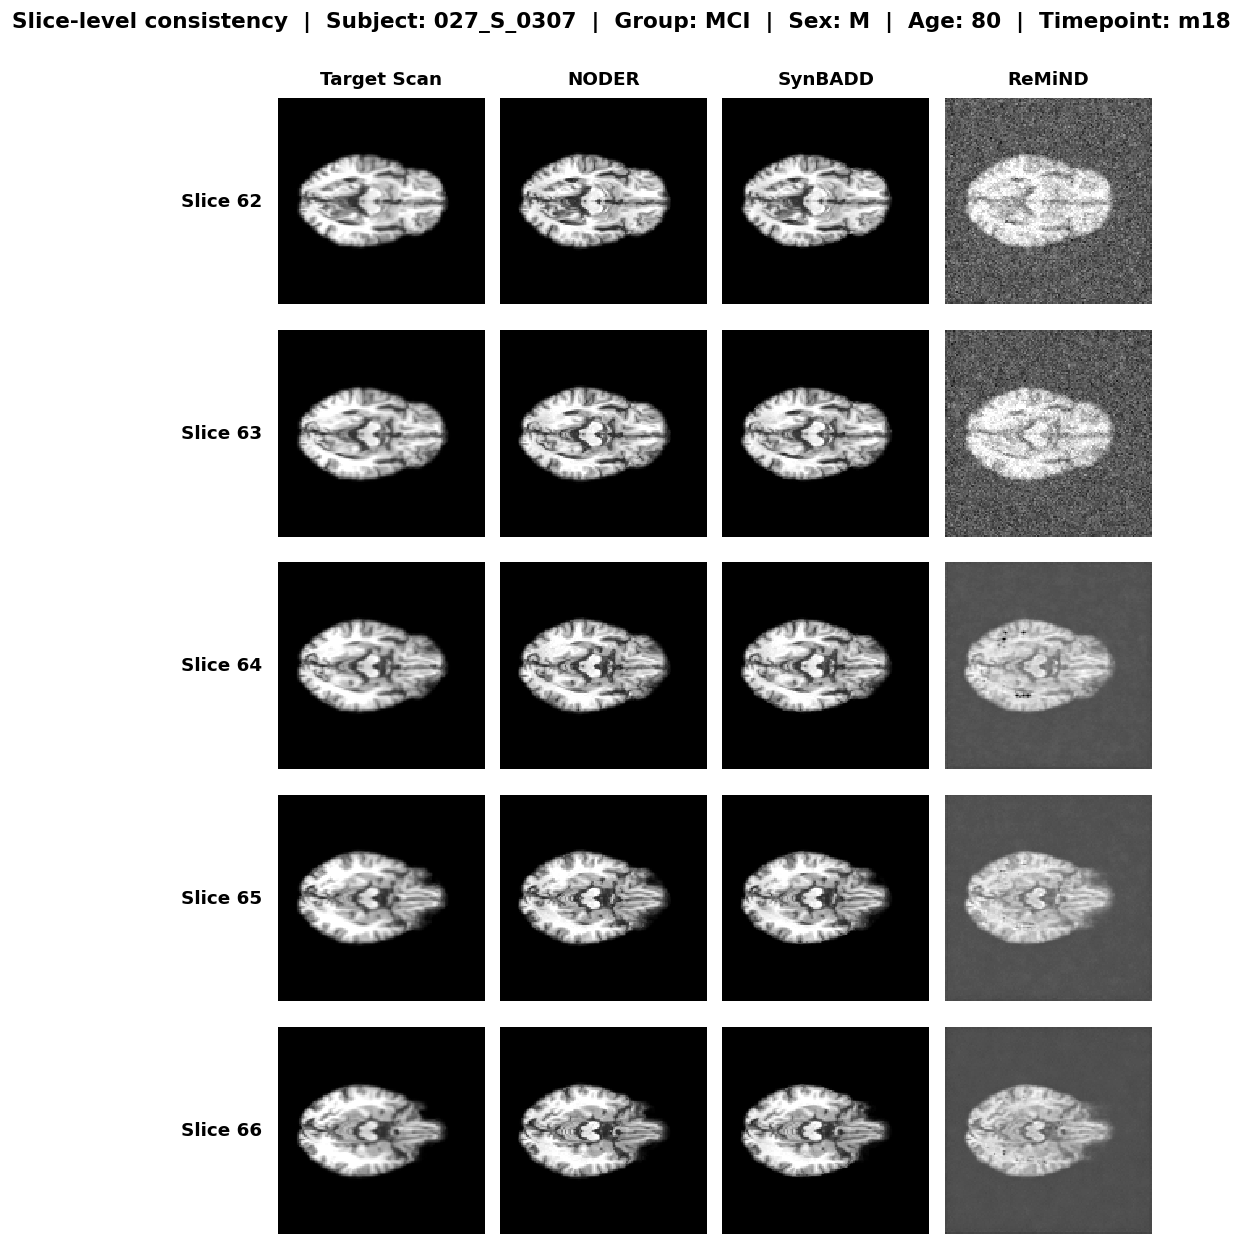

In [42]:
# SOTA slice-level consistency around the middle axial slice for one selected case.
r = selected.iloc[SELECTED_INDEX]
slice_methods = ['target', 'NODER', 'SynBADD', 'ReMiND']
volumes = {m: robust01(load_volume(r[m])) for m in slice_methods}
center = volumes['target'].shape[2] // 2
slice_ids = list(range(center - 2, center + 3))
fig = plt.figure(figsize=(9.2, 10.8), facecolor='white')
gs = fig.add_gridspec(len(slice_ids), 5, width_ratios=[0.72, 1, 1, 1, 1],
                      hspace=0.10, wspace=0.08,
                      left=0.04, right=0.98, top=0.91, bottom=0.03)
slice_titles = ['Target Scan', 'NODER', 'SynBADD', 'ReMiND']
for row_i, z in enumerate(slice_ids):
    index_ax = fig.add_subplot(gs[row_i, 0])
    index_ax.axis('off')
    index_ax.text(1.0, 0.5, f'Slice {z}', ha='right', va='center',
                  fontsize=11, fontweight='bold')
    for col_i, method in enumerate(slice_methods, start=1):
        ax = fig.add_subplot(gs[row_i, col_i])
        ax.imshow(axial(volumes[method], z), cmap='gray', vmin=0, vmax=1,
                  interpolation='nearest')
        ax.set_box_aspect(1)
        ax.axis('off')
        if row_i == 0:
            ax.set_title(slice_titles[col_i - 1], fontsize=11, fontweight='bold', pad=8)
fig.suptitle(f'Slice-level consistency  |  Subject: {r.subject}  |  Group: {r.group}  |  '
             f'Sex: {r.sex}  |  Age: {r.age}  |  Timepoint: {r.visit}',
             fontsize=13, fontweight='semibold', y=0.975)
slice_consistency_path = save_figure(fig, 'slice-level-consistence', r.subject)
plt.show()